# Lab 4 — Build the Audience, Then Buy It
Name: Yuliia Romaniuk | Group: KM-41

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab4-tv-audiences/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")
survey = pd.read_csv(f"{DATA}/purchase_survey.txt", sep="\t", dtype=str, keep_default_na=False)
survey_layout = pd.read_csv(f"{DATA}/purchase_survey_layout.txt", sep="\t", dtype=str)
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")
universe = pd.read_parquet(f"{DATA}/universe.parquet")

100%|██████████| 74.2M/74.2M [00:02<00:00, 31.2MB/s]

Extracting files...


### Preparing the data

In [2]:
import re
import numpy as np

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

OCT_START, OCT_END = pd.Timestamp("2024-10-01"), pd.Timestamp("2024-10-31")


def broadcast_day(ts):
    """A broadcast day runs 06:00-05:59: 01:00 on Oct 15 belongs to Oct 14."""
    return (ts - pd.Timedelta(hours=6)).dt.normalize()


programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])
network_names = programs.drop_duplicates("network_code").set_index("network_code")["network_name"]

# ---- panel: people are R and L only; October; that day's weight ----
dw = daily_weights.copy()
dw["broadcast_date"] = pd.to_datetime(dw["broadcast_date"])
dw = dw[dw["broadcast_date"].between(OCT_START, OCT_END) & dw["resp_type"].isin(["R", "L"])]
N_DAYS = dw["broadcast_date"].nunique()

va = viewer_attributes.merge(attributes, on="attr_id", how="left")
rtype = va[va["attr_group"] == "Respondent type"].drop_duplicates("respondent_id").set_index("respondent_id")["attr_name"]
rtype = rtype.str.extract(r"^\s*([A-Z])\s*:", expand=False)          # 'R: panel member' -> 'R'
age = va[va["attr_id"] == 300].drop_duplicates("respondent_id").set_index("respondent_id")["value"]
sex = va[va["attr_id"].isin([201, 202])].drop_duplicates("respondent_id").set_index("respondent_id")["attr_id"].map({201: "M", 202: "W"})

people = pd.DataFrame({"rtype": rtype})
people["age"] = age
people["sex"] = sex
people["adult"] = people["rtype"].isin(["R", "L"]) & (people["age"] >= 18)
people["age_group"] = pd.cut(people["age"], [17, 34, 54, 200], labels=["18-34", "35-54", "55+"])
print("Respondent types in viewer_attributes:", people["rtype"].value_counts().to_dict())


def audience_size(ids, by_day=False):
    """Each broadcast day: sum of daily weights of members in-tab; size = mean over the October days."""
    daily = dw[dw["respondent_id"].isin(ids)].groupby("broadcast_date")["weight"].sum()
    daily = daily.reindex(sorted(dw["broadcast_date"].unique()), fill_value=0)
    return daily if by_day else daily.mean()


# ---- rate card pricing (Lab 2 rules: program rows win over time rows) ----
def to_minutes(hhmm):
    """Broadcast clock 'HH:MM' -> minutes since 06:00 (25:37 -> 25*60 + 37 - 360)."""
    h, m = str(hhmm).split(":")
    return int(h) * 60 + int(m) - 360


def price(tels):
    """Add daypart (from the time rows) and cost per :30 (program row if there is one, else time row)."""
    t = tels[["telecast_id", "network_code", "program_name", "start_ts"]].copy()
    shifted = t["start_ts"] - pd.Timedelta(hours=6)
    t["b_weekday"] = shifted.dt.dayofweek
    t["b_minute"] = shifted.dt.hour * 60 + shifted.dt.minute

    time_rows = rate_card[rate_card["program_name"].isna()].copy()
    time_rows["start_min"] = time_rows["start_time"].apply(to_minutes)
    time_rows["end_min"] = time_rows["end_time"].apply(to_minutes)
    time_rows = time_rows.explode("weekdays")
    time_rows["b_weekday"] = time_rows["weekdays"].astype(int)
    by_time = t.merge(time_rows[["network_code", "b_weekday", "start_min", "end_min", "daypart", "cost_30s_usd"]],
                      on=["network_code", "b_weekday"])
    by_time = by_time[(by_time["start_min"] <= by_time["b_minute"]) & (by_time["b_minute"] < by_time["end_min"])]
    by_time = by_time.drop_duplicates("telecast_id").set_index("telecast_id")

    prog_rows = rate_card[rate_card["program_name"].notna()].drop_duplicates(["network_code", "program_name"])
    by_prog = t.merge(prog_rows[["network_code", "program_name", "cost_30s_usd"]], on=["network_code", "program_name"])
    by_prog = by_prog.set_index("telecast_id")["cost_30s_usd"]

    out = tels.set_index("telecast_id").copy()
    out["daypart"] = by_time["daypart"]
    out["cost_30s"] = by_prog.reindex(out.index).fillna(by_time["cost_30s_usd"])
    out["price_row"] = np.where(out.index.isin(by_prog.index), "program", "time")
    return out.reset_index()


oct_tel = programs[programs["broadcast_date"].between(OCT_START, OCT_END)]
oct_tel = price(oct_tel)
if "daypart" in programs.columns:            # use the schedule's own daypart if the file has one
    oct_tel["daypart"] = programs.set_index("telecast_id")["daypart"].reindex(oct_tel["telecast_id"]).values
oct_tel["minutes"] = (oct_tel["end_ts"] - oct_tel["start_ts"]).dt.total_seconds() / 60
prime = oct_tel[oct_tel["daypart"] == "Prime"]
print("October telecasts:", len(oct_tel), "| in Prime:", len(prime), "| without a price:", oct_tel["cost_30s"].isna().sum())

# ---- minutes each person (R/L) viewed each telecast; weighted with that day's weight ----
person_view = viewings[viewings["resp_type"].isin(["R", "L"])]
view_by_net = {net: df for net, df in person_view.groupby("network_code")}


def viewed_minutes(tels):
    """One row per (telecast, person) with minutes of the telecast viewed (on its network) and that day's weight."""
    parts = []
    for t in tels.itertuples():
        v = view_by_net.get(t.network_code)
        if v is None:
            continue
        v = v[(v["start_ts"] < t.end_ts) & (v["end_ts"] > t.start_ts)]
        mins = ((v["end_ts"].clip(upper=t.end_ts) - v["start_ts"].clip(lower=t.start_ts)).dt.total_seconds() / 60)
        mins = mins.groupby(v["respondent_id"]).sum()
        parts.append(pd.DataFrame({"telecast_id": t.telecast_id, "broadcast_date": t.broadcast_date,
                                   "respondent_id": mins.index, "minutes": mins.values}))
    vm = pd.concat(parts, ignore_index=True)
    return vm.merge(dw[["respondent_id", "broadcast_date", "weight"]], on=["respondent_id", "broadcast_date"])


def telecast_ratings(tels, vm, ids):
    """Average-minute audience and rating of each telecast for an audience (set of respondent ids)."""
    size_by_day = audience_size(ids, by_day=True)
    m = vm[vm["respondent_id"].isin(ids)]
    wmin = (m["weight"] * m["minutes"]).groupby(m["telecast_id"]).sum()
    t = tels.set_index("telecast_id")[["network_code", "program_name", "broadcast_date", "minutes"]].copy()
    t["viewers"] = wmin.reindex(t.index).fillna(0) / t["minutes"]          # average-minute audience
    t["rating"] = 100 * t["viewers"] / t["broadcast_date"].map(size_by_day)
    return t


def label(program, network):
    return f"{program} ({network})"

Respondent types in viewer_attributes: {'R': 10095, 'H': 4256, 'L': 121}
October telecasts: 5841 | in Prime: 1043 | without a price: 0


## Task 1.0 — Clean the survey file

In [3]:
print("Layout file:")
display(survey_layout)
print("Raw VALUE spellings:", survey["VALUE"].value_counts(dropna=False).head(15).to_dict())

# ---------- the layout: what each answer code means ----------
lay = survey_layout.copy()
lay.columns = [c.strip() for c in lay.columns]
lay["RECTYPE"] = lay["RECTYPE"].str.strip().str.upper()
lay["KEYWORD"] = lay["KEYWORD"].str.strip()
lay["SAMPLE"] = pd.to_numeric(lay["SAMPLE"], errors="coerce")
lay["question"] = lay["Text"].where(lay["RECTYPE"] == "H").ffill()          # each answer under its question
ans = lay[lay["RECTYPE"] == "B"].copy()
txt = (ans["Text"].fillna("") + " | " + ans["Variable"].fillna("") + " | " + ans["question"].fillna("")).str.lower()


def kind_of(row_text, answer_text):
    a = answer_text.lower()
    if re.search(r"\bpairs?\b", row_text) and re.search(r"\d", a):
        return "pairs"
    if re.search(r"\bany\b", a) or re.search(r"(bought|purchased) (any|athletic)", a):
        return "any"
    if "brand" in row_text:
        return "brand"
    return "other"


ans["kind"] = [kind_of(r, a) for r, a in zip(txt, ans["Text"].fillna(""))]
ans["n_pairs"] = ans["Text"].str.extract(r"(\d+)", expand=False).astype(float).where(ans["kind"] == "pairs")
ans.loc[(ans["kind"] == "pairs") & ans["Text"].str.contains(r"\+|or more|more than", case=False), "n_pairs"] = 3
ans["n_pairs"] = ans["n_pairs"].clip(upper=3)
print("How the answer codes are read:")
display(ans[["KEYWORD", "Text", "kind", "n_pairs", "SAMPLE"]])

ANY = ans.loc[ans["kind"] == "any", "KEYWORD"].tolist()
PAIRS = ans.loc[ans["kind"] == "pairs"].set_index("KEYWORD")["n_pairs"]
BRANDS = ans.loc[ans["kind"] == "brand"].set_index("KEYWORD")["Text"].str.strip()
KESTREL = BRANDS[BRANDS.str.contains("kestrel", case=False)].index[0]
valid_kw = set(ans["KEYWORD"])
kw_by_upper = {k.upper(): k for k in valid_kw}

# ---------- clean the rows, counting every kind of problem ----------
log = []                                          # (kind of bad record, rows hit, what we did)
s = survey.copy()
s.columns = [c.strip().upper() for c in s.columns]
n_raw = len(s)


def note(kind, mask, action):
    log.append({"bad record": kind, "rows": int(mask.sum()), "action": action})


blank = (s["RESPID"].str.strip() == "") & (s["KEYWORD"].str.strip() == "")
header = s["RESPID"].str.strip().str.upper().eq("RESPID")
note("Empty line or repeated header", blank | header, "dropped")
s = s[~(blank | header)].copy()

rid = s["RESPID"].str.strip().str.replace(r"\.0+$", "", regex=True).str.replace(r"^0+(?=\d)", "", regex=True)
note("RESPID written differently (spaces, leading zeros, '.0')", rid != s["RESPID"], "fixed to the plain id")
bad_id = ~rid.str.fullmatch(r"\d+")
note("RESPID not a number", bad_id, "dropped")
s["RESPID"] = rid
s = s[~bad_id].copy()
s["respondent_id"] = s["RESPID"].astype("int64")

kw = s["KEYWORD"].str.strip()
fixed_kw = kw.str.upper().map(kw_by_upper)
note("KEYWORD with wrong case or spaces", fixed_kw.notna() & (fixed_kw != s["KEYWORD"]), "fixed to the layout code")
note("KEYWORD not in the layout", fixed_kw.isna(), "dropped")
s["KEYWORD"] = fixed_kw
s = s[s["KEYWORD"].notna()].copy()

val = s["VALUE"].str.strip().str.upper()
YES = {"1", "1.0", "Y", "YES", "TRUE", "T", "X"}
standard_yes = s["VALUE"].value_counts().idxmax()                 # the vendor's usual spelling of yes
note("VALUE 'yes' spelled differently", val.isin(YES) & (s["VALUE"] != standard_yes), "kept as yes")
note("VALUE not a yes (no / 0 / blank)", ~val.isin(YES), "dropped")
s = s[val.isin(YES)].copy()

in_va = s["respondent_id"].isin(people.index)
is_adult = s["respondent_id"].map(people["adult"]).fillna(False).astype(bool)
kid = in_va & s["respondent_id"].map(people["rtype"]).isin(["R", "L"]) & ~is_adult
note("RESPID not in the panel", ~in_va, "dropped")
note("RESPID of a child (under 18)", kid, "dropped")
note("RESPID of a household/guest record (H, S)", in_va & ~is_adult & ~kid, "dropped")
s = s[is_adult].copy()

dup = s.duplicated(["respondent_id", "KEYWORD"])
note("Same person and keyword twice", dup, "kept one")
s = s[~dup].copy()

s["n_pairs"] = s["KEYWORD"].map(PAIRS)
pair_rows = s[s["n_pairs"].notna()]
two_counts = pair_rows["respondent_id"].duplicated(keep=False)
n_two = pair_rows.loc[two_counts, "respondent_id"].nunique()
ranked = pair_rows.sort_values("n_pairs", ascending=False)
lower_idx = ranked.index[ranked.duplicated("respondent_id")]          # every count but the highest
note("Person with two (or more) pair counts", pd.Series(True, index=lower_idx), "kept the higher count")
s = s.drop(lower_idx)
clean = s

# ---------- one row per adult panel member ----------
adult_ids = people.index[people["adult"]]
resp = pd.DataFrame(index=pd.Index(adult_ids, name="respondent_id"))
resp["pairs"] = clean.dropna(subset=["n_pairs"]).groupby("respondent_id")["n_pairs"].max()
for code, brand in BRANDS.items():
    resp[brand] = resp.index.isin(clean.loc[clean["KEYWORD"] == code, "respondent_id"])
resp["buyer"] = resp.index.isin(clean["respondent_id"])          # Any, a pair count or a brand
resp["pairs"] = resp["pairs"].where(resp["buyer"], 0)
resp["any_row"] = resp.index.isin(clean.loc[clean["KEYWORD"].isin(ANY), "respondent_id"])
print("Buyers without an Any row (made buyers by the rule):", int((resp["buyer"] & ~resp["any_row"]).sum()))
print("Buyers without a pair count:", int((resp["buyer"] & resp["pairs"].isna()).sum()))

print("Survey data rows:", n_raw)
print("Clean yes answers:", len(clean))
print("Adult panel members:", len(resp))
print("Non-buyers:", int((~resp["buyer"]).sum()))
print("People with two pair counts:", n_two)

display(pd.DataFrame(log))

# check against the layout's SAMPLE
check = ans.set_index("KEYWORD")[["Text", "SAMPLE"]].copy()
check["your_count"] = clean.groupby("KEYWORD")["respondent_id"].nunique().reindex(check.index).fillna(0).astype(int)
if ANY:
    check.loc[ANY, "your_count_incl_rule"] = int(resp["buyer"].sum())
check["difference"] = check["your_count"] - check["SAMPLE"]
display(check)

# what the file as delivered would have said (no cleaning at all)
raw_kestrel_rows = (survey["KEYWORD"] == KESTREL).sum()
raw_kestrel_ids = survey.loc[survey["KEYWORD"] == KESTREL, "RESPID"].nunique()
raw_buyer_ids = survey.loc[survey["RESPID"].str.strip() != "", "RESPID"].nunique()
print("Kestrel buyers, clean:", int(resp[BRANDS[KESTREL]].sum()),
      "| raw rows:", raw_kestrel_rows, "| raw distinct RESPIDs:", raw_kestrel_ids)
print("Share of adults who bought, clean:", f'{resp["buyer"].mean():.3f}',
      "| raw (distinct RESPIDs in file / adults):", f"{raw_buyer_ids / len(resp):.3f}")

Layout file:


,HIERARCHY,RECTYPE,KEYWORD,Text,Variable,SAMPLE
0,1,H,H7100,Athletic shoes,APPAREL > ATHLETIC SHOES,NaN
1,1.1,H,H7101,Pairs bought in last 12 months,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,NaN
2,1.1.1,B,X710100,Any,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,4779
3,1.1.1,B,X710101,1 pair,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,1810
4,1.1.1,B,X710102,2 pairs,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,1308
5,1.1.1,B,X710103,3 or more pairs,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,1661
6,1.2,H,H7102,Brands bought in last 12 months,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,NaN
7,1.2.1,B,X710201,STRIDE,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,1563
8,1.2.1,B,X710202,KESTREL,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,354
9,1.2.1,B,X710203,EASYWALK,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,1050


Raw VALUE spellings: {'1': 16410, '1.0': 262, 'y': 246, 'TRUE': 241, '0': 237, 'Y': 228, 'yes': 217, '0.0': 129, 'N': 127, 'no': 126, '': 124, 'VALUE': 2}
How the answer codes are read:


,KEYWORD,Text,kind,n_pairs,SAMPLE
2,X710100,Any,any,NaN,4779.0
3,X710101,1 pair,pairs,1.0,1810.0
4,X710102,2 pairs,pairs,2.0,1308.0
5,X710103,3 or more pairs,pairs,3.0,1661.0
7,X710201,STRIDE,brand,NaN,1563.0
8,X710202,KESTREL,brand,NaN,354.0
9,X710203,EASYWALK,brand,NaN,1050.0
10,X710298,OTHER BRAND,brand,NaN,2739.0
11,X710299,DON'T KNOW,brand,NaN,371.0


Buyers without an Any row (made buyers by the rule): 238
Buyers without a pair count: 0
Survey data rows: 18349
Clean yes answers: 15397
Adult panel members: 8010
Non-buyers: 3231
People with two pair counts: 113


/tmp/ipykernel_806/3893884065.py:80: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  is_adult = s["respondent_id"].map(people["adult"]).fillna(False).astype(bool)


,bad record,rows,action
0,Empty line or repeated header,2,dropped
1,"RESPID written differently (spaces, leading ze...",1455,fixed to the plain id
2,RESPID not a number,1,dropped
3,KEYWORD with wrong case or spaces,1059,fixed to the layout code
4,KEYWORD not in the layout,738,dropped
5,VALUE 'yes' spelled differently,1142,kept as yes
6,VALUE not a yes (no / 0 / blank),742,dropped
7,RESPID not in the panel,150,dropped
8,RESPID of a child (under 18),273,dropped
9,"RESPID of a household/guest record (H, S)",0,dropped


,Text,SAMPLE,your_count,your_count_incl_rule,difference
KEYWORD,,,,,
X710100,Any,4779.0,4541,4779.0,-238.0
X710101,1 pair,1810.0,1810,NaN,0.0
X710102,2 pairs,1308.0,1308,NaN,0.0
X710103,3 or more pairs,1661.0,1661,NaN,0.0
X710201,STRIDE,1563.0,1563,NaN,0.0
X710202,KESTREL,354.0,354,NaN,0.0
X710203,EASYWALK,1050.0,1050,NaN,0.0
X710298,OTHER BRAND,2739.0,2739,NaN,0.0
X710299,DON'T KNOW,371.0,371,NaN,0.0


Kestrel buyers, clean: 354 | raw rows: 516 | raw distinct RESPIDs: 495
Share of adults who bought, clean: 0.597 | raw (distinct RESPIDs in file / adults): 0.885


**Answer:** The file broke all three of the vendor's promises, and it also had formatting problems. Of **18,349** data rows, **15,397** clean yes answers are left:

| Bad record | Rows | What I did |
|---|---|---|
| Empty line / repeated header row | 2 | dropped |
| RESPID written differently (spaces, leading zeros, `.0`) | 1,455 | fixed to the plain id |
| RESPID not a number | 1 | dropped |
| KEYWORD in the wrong case or with spaces | 1,059 | fixed to the layout code |
| KEYWORD not in the layout | 738 | dropped |
| VALUE "yes" written as `1.0`, `y`, `Y`, `TRUE`, `yes` | 1,142 | kept as yes |
| VALUE not a yes (`0`, `0.0`, `N`, `no`, blank) | 742 | dropped |
| RESPID not in the panel | 150 | dropped |
| RESPID of a child (under 18) | 273 | dropped |
| Same person and keyword twice | 933 | kept one |
| Person with two pair counts (113 people) | 113 | kept the higher count |

After cleaning, **every** keyword count equals the layout's SAMPLE exactly: 1,810 / 1,308 / 1,661 for 1 / 2 / 3+ pairs, 354 for Kestrel, and the other brands too. The only difference is the *Any* row: 4,541 people have one, but **238** more bought a brand or gave a pair count without it. Counting them as buyers by the rule gives exactly **4,779**, the layout's SAMPLE. That leaves **8,010** adult panel members, of whom **3,231** bought nothing.

**Using the file as delivered** would have been badly wrong. Kestrel shows **516 rows** (495 distinct RESPIDs) instead of **354** buyers: **+46%** (+40% by id). This is because of duplicates, ids written two ways, children and non-panel ids. Counting everyone in the file as a buyer gives a share of **0.885** of adults instead of **0.597**, about 29 points too high, because the file also contains "no" answers, children and people who are not in the panel.

## Task 1.1 — Four definitions

In [4]:
KESTREL_COL = BRANDS[KESTREL]
audiences = {
    "Adults 18+": resp.index,
    "Shoe buyers": resp.index[resp["buyer"]],
    "Heavy buyers (3+)": resp.index[resp["pairs"] >= 3],
    "Kestrel buyers": resp.index[resp[KESTREL_COL]],
    "Adults 25-54": resp.index[people.loc[resp.index, "age"].between(25, 54)],
}
sizes = {name: audience_size(ids) for name, ids in audiences.items()}

print("Adults 18+ (M):", f'{sizes["Adults 18+"] / 1e6:.1f}')
print("Shoe buyers (M):", f'{sizes["Shoe buyers"] / 1e6:.1f}')
print("Heavy buyers, 3+ pairs (M):", f'{sizes["Heavy buyers (3+)"] / 1e6:.1f}')
print("Kestrel buyers (M):", f'{sizes["Kestrel buyers"] / 1e6:.1f}')
print("Adults 25-54 (M):", f'{sizes["Adults 25-54"] / 1e6:.1f}')
print("Kestrel buyers in panel (n):", len(audiences["Kestrel buyers"]))

size_tbl = pd.DataFrame({"size_M": pd.Series(sizes) / 1e6, "panel_n": {k: len(v) for k, v in audiences.items()}})
size_tbl["share_of_adults"] = size_tbl["size_M"] / size_tbl.loc["Adults 18+", "size_M"]
display(size_tbl.round({"size_M": 1, "share_of_adults": 3}))

Adults 18+ (M): 252.6
Shoe buyers (M): 148.1
Heavy buyers, 3+ pairs (M): 49.6
Kestrel buyers (M): 10.0
Adults 25-54 (M): 123.7
Kestrel buyers in panel (n): 354


,size_M,panel_n,share_of_adults
Adults 18+,252.6,8010,1.000
Shoe buyers,148.1,4779,0.586
Heavy buyers (3+),49.6,1661,0.196
Kestrel buyers,10.0,354,0.040
Adults 25-54,123.7,4814,0.490


## Task 1.2 — Who are they?

In [5]:
groups = {f"{s_}{a}": people.index[(people["sex"] == s_) & (people["age_group"] == a)]
          for a in ["18-34", "35-54", "55+"] for s_ in ["M", "W"]}
share = pd.DataFrame({
    aud: {g: audience_size(ids.intersection(gids)) / sizes[aud] for g, gids in groups.items()}
    for aud, ids in audiences.items()
})
index = (share.div(share["Adults 18+"], axis=0) * 100).round(0)
profile = pd.concat({"share": share.round(3), "index": index}, axis=1)
display(profile)

share                                                                index                                                          
       Adults 18+ Shoe buyers Heavy buyers (3+) Kestrel buyers Adults 25-54 Adults 18+ Shoe buyers Heavy buyers (3+) Kestrel buyers Adults 25-54
M18-34      0.144       0.140             0.111          0.118        0.174      100.0        97.0              77.0           82.0        121.0
W18-34      0.144       0.140             0.139          0.181        0.174      100.0        98.0              97.0          126.0        121.0
M35-54      0.160       0.158             0.138          0.189        0.326      100.0        99.0              87.0          119.0        204.0
W35-54      0.160       0.178             0.226          0.265        0.326      100.0       111.0             142.0          166.0        204.0
M55+        0.185       0.186             0.189          0.126        0.000      100.0       101.0             102.0           68.0          0.0
W55+        0.208       0.197             0.196          0.121        0.000      100.0        95.0              94.0           58.0          0.0

**Answer:**

**Which definition for Kestrel: heavy buyers (3+ pairs), 49.6 M people, 19.6% of adults.** It is exactly the client's brief, and it has a real profile: women 35–54 index **142**, while men 18–34 (77) and men 35–54 (87) are under-represented. It is also big enough to measure: **1,661** panelists. *Kestrel buyers* (10.0 M) are a sharper profile (women 35–54: 166, women 18–34: 126; men and women 55+: 68 / 58). But they are only **354** panelists, too few for stable program ratings (Task 2.3), and they are existing customers, while a flight also has to win new buyers. *Adults 25–54* is the demo a TV buyer would use instead. It is a completely different audience: it **drops everyone 55+** (index 0), although 55+ makes up 39% of heavy buyers, and it over-weights men 35–54 (204), whom the brand's buyers under-index on.

**Why "athletic-shoe buyers" looks like all adults:** 59% of adults bought at least one pair in a year, so the audience *is* most of the population. Its indexes are 95–111 in every group, and nearly everyone looks like a "buyer". A definition that includes almost everyone cannot target anyone. It is the definition (how often, which brand) that makes an audience distinctive, and here the size goes from 148 M to 50 M to 10 M depending on it.

**One limit of fused data:** the purchase answers were attached to panelists **through their demographics (age, sex, income) only**. So a program's heavy-buyer audience just mirrors its demographic mix. The data cannot show whether people who really buy three pairs a year watch differently from demographically identical non-buyers (for example, more sports). It also cannot link seeing an ad to buying Kestrel, because the buyers and the viewers were never measured as the same people.

## Task 2.1 — Programs by audience

In [6]:
EIGHT = [("NBC", "NFL Football", "Sunday Night Football"), ("ABC", "NFL Football", "Monday Night Football"),
         ("ABC", "Dancing with the Stars", None), ("CBS", "NCIS", None), ("FNC", "Hannity", None),
         ("HGTV", "Unsellable Houses", None), ("FOOD", "Halloween Wars", None), ("FX", "Grotesquerie", None)]


def find_telecasts(net, name):
    """October Prime telecasts of a program; exact name first, then 'contains'."""
    t = prime[(prime["network_code"] == net) & (prime["program_name"].str.strip().str.lower() == name.lower())]
    if t.empty:
        t = prime[(prime["network_code"] == net) & prime["program_name"].str.contains(name, case=False, regex=False)]
    return t


sel = []
for net, name, alias in EIGHT:
    t = find_telecasts(net, name).copy()
    t["label"] = label(alias or name, net)
    sel.append(t)
    print(f"{label(alias or name, net):40s} Prime telecasts in October: {len(t)}")
sel = pd.concat(sel)

# telecasts needed anywhere below: the eight programs + Prime on the five big networks (Task 4)
BIG5 = ["CBS", "NBC", "ABC", "FOX", "FNC"]
need = pd.concat([sel, prime[prime["network_code"].isin(BIG5)]]).drop_duplicates("telecast_id")
vm = viewed_minutes(need)

heavy_ids = audiences["Heavy buyers (3+)"]
adults_r = telecast_ratings(sel, vm, audiences["Adults 18+"])
heavy_r = telecast_ratings(sel, vm, heavy_ids)

t2 = sel.set_index("telecast_id")[["label", "cost_30s"]].copy()
t2["adults_rating"] = adults_r["rating"]
t2["adults_viewers"] = adults_r["viewers"]
t2["target_rating"] = heavy_r["rating"]
t2["target_viewers"] = heavy_r["viewers"]
prog = t2.groupby("label", sort=False).agg(telecasts=("cost_30s", "size"), adults_rating=("adults_rating", "mean"),
                                           target_rating=("target_rating", "mean"), adults_viewers=("adults_viewers", "mean"),
                                           target_viewers=("target_viewers", "mean"), cost_30s=("cost_30s", "mean"))
prog["composition"] = prog["target_viewers"] / prog["adults_viewers"]
prog["index"] = prog["target_rating"] / prog["adults_rating"] * 100
prog["adults_CPM"] = prog["cost_30s"] / (prog["adults_viewers"] / 1000)
prog["target_CPM"] = prog["cost_30s"] / (prog["target_viewers"] / 1000)

show = pd.DataFrame({
    "telecasts": prog["telecasts"],
    "adults_rating": prog["adults_rating"].round(2),
    "target_rating": prog["target_rating"].round(2),
    "target_viewers_k": (prog["target_viewers"] / 1000).round(0),
    "composition": prog["composition"].round(3),
    "index": prog["index"].round(0),
    "cost_30s_usd": prog["cost_30s"].round(0),
    "adults_CPM": prog["adults_CPM"].round(2),
    "target_CPM": prog["target_CPM"].round(2),
})
display(show)
print("Heavy buyers' share of adults:", f'{sizes["Heavy buyers (3+)"] / sizes["Adults 18+"]:.3f}')
print("Target universe (M):", f'{sizes["Heavy buyers (3+)"] / 1e6:.1f}')

Sunday Night Football (NBC)              Prime telecasts in October: 4
Monday Night Football (ABC)              Prime telecasts in October: 3
Dancing with the Stars (ABC)             Prime telecasts in October: 9
NCIS (CBS)                               Prime telecasts in October: 3
Hannity (FNC)                            Prime telecasts in October: 22
Unsellable Houses (HGTV)                 Prime telecasts in October: 13
Halloween Wars (FOOD)                    Prime telecasts in October: 9
Grotesquerie (FX)                        Prime telecasts in October: 25


,telecasts,adults_rating,target_rating,target_viewers_k,composition,index,cost_30s_usd,adults_CPM,target_CPM
label,,,,,,,,,
Sunday Night Football (NBC),4,5.82,5.79,2865.0,0.195,99.0,487200.0,33.12,170.05
Monday Night Football (ABC),3,8.93,8.36,4149.0,0.184,94.0,723600.0,32.09,174.40
Dancing with the Stars (ABC),9,3.25,3.14,1564.0,0.191,97.0,158600.0,19.33,101.39
NCIS (CBS),3,2.21,2.43,1206.0,0.216,110.0,178800.0,32.09,148.22
Hannity (FNC),22,1.09,0.84,417.0,0.152,77.0,39900.0,14.50,95.71
Unsellable Houses (HGTV),13,0.50,0.64,317.0,0.249,127.0,12900.0,10.12,40.66
Halloween Wars (FOOD),9,0.28,0.33,162.0,0.228,116.0,9700.0,13.67,59.90
Grotesquerie (FX),25,0.26,0.25,124.0,0.188,96.0,7592.0,11.50,61.11


Heavy buyers' share of adults: 0.196
Target universe (M): 49.6


## Task 2.2 — Index, volume or price?

In [7]:
print("Highest index (program):", prog["index"].idxmax())
print("Most target viewers (program):", prog["target_viewers"].idxmax())
print("Lowest target CPM (program):", prog["target_CPM"].idxmin())

Highest index (program): Unsellable Houses (HGTV)
Most target viewers (program): Monday Night Football (ABC)
Lowest target CPM (program): Unsellable Houses (HGTV)


**Answer:** **Partly.** *Unsellable Houses (HGTV)* has both the **highest index (127)** and the **lowest target CPM ($40.66)**. But it delivers only **317 k** heavy buyers per average minute. The **most target viewers** come from *Monday Night Football (ABC)*: **4.15 M**, 13 times as many, with an index of only **94** (below average) and a target CPM of $174.

**To a client who wants "only the highest index":** the index measures **concentration**, not size. Unsellable Houses is a small program where heavy buyers are a bit more concentrated, but even there **75% of viewers are not heavy buyers** (composition 0.249). Buying "only the highest index" means buying tiny audiences again and again: you reach the same few hundred thousand people many times and miss most of the 49.6 M target. A program with an index below 100 but a huge audience (MNF, SNF) reaches more target people in one spot than a week of high-index cable. That is the shampoo example: the best "index" network can deliver far fewer actual buyers than a mass program. What the client pays for is **target impressions at a target CPM, and reach**. So rank by target CPM, use volume to build reach, and treat the index as a tie-breaker. Here the heavy-buyer index only ranges from 77 to 127, because the fused attribute only follows demographics.

## Task 2.3 — Kestrel buyers

In [8]:
kestrel_ids = audiences["Kestrel buyers"]
kes_r = telecast_ratings(sel, vm, kestrel_ids)
t2["kestrel_rating"] = kes_r["rating"]

# how many panelists stand behind each index: in-target viewers per telecast (unweighted)
per_tel = vm[vm["telecast_id"].isin(sel["telecast_id"])]
t2["heavy_panelists"] = per_tel[per_tel["respondent_id"].isin(heavy_ids)].groupby("telecast_id").size()
t2["kestrel_panelists"] = per_tel[per_tel["respondent_id"].isin(kestrel_ids)].groupby("telecast_id").size()
t2[["heavy_panelists", "kestrel_panelists"]] = t2[["heavy_panelists", "kestrel_panelists"]].fillna(0)

g = t2.groupby("label", sort=False)
kes = pd.DataFrame({
    "heavy_index": prog["index"],
    "kestrel_index": g["kestrel_rating"].mean() / prog["adults_rating"] * 100,
    "heavy_panelists_per_telecast": g["heavy_panelists"].mean(),
    "kestrel_panelists_per_telecast": g["kestrel_panelists"].mean(),
    # telecast-to-telecast spread of each index (same program, different weeks)
    "heavy_index_sd": (t2["target_rating"] / t2["adults_rating"] * 100).groupby(t2["label"], sort=False).std(),
    "kestrel_index_sd": (t2["kestrel_rating"] / t2["adults_rating"] * 100).groupby(t2["label"], sort=False).std(),
})
display(kes.round(1))
print("Panel size: heavy buyers", len(heavy_ids), "| Kestrel buyers", len(kestrel_ids))
print("Spread of the index across programs (SD): heavy", f'{kes["heavy_index"].std():.1f}',
      "| Kestrel", f'{kes["kestrel_index"].std():.1f}')

,heavy_index,kestrel_index,heavy_panelists_per_telecast,kestrel_panelists_per_telecast,heavy_index_sd,kestrel_index_sd
label,,,,,,
Sunday Night Football (NBC),99.3,98.5,329.0,75.2,7.8,8.3
Monday Night Football (ABC),93.6,85.9,292.7,69.3,5.8,5.4
Dancing with the Stars (ABC),96.8,82.7,122.6,23.4,7.6,23.4
NCIS (CBS),110.1,56.5,86.3,11.0,4.0,25.7
Hannity (FNC),77.1,42.6,15.9,2.1,18.7,28.1
Unsellable Houses (HGTV),126.8,76.9,25.4,4.0,31.4,32.7
Halloween Wars (FOOD),116.2,95.2,13.7,2.8,41.4,64.9
Grotesquerie (FX),95.9,129.6,11.4,3.1,37.3,75.8


Panel size: heavy buyers 1661 | Kestrel buyers 354
Spread of the index across programs (SD): heavy 15.3 | Kestrel 26.5


**Answer:** The Kestrel index swings far more than the heavy-buyer index. Across the eight programs its SD is **26.5** vs **15.3**: NCIS **56** (heavy 110), Hannity **43** (77), Grotesquerie **130** (96). Within the same program from telecast to telecast it is also much less stable: SD of **65** for Halloween Wars and **76** for Grotesquerie, vs 41 and 37 for heavy buyers.

**Why:** it is a **small-sample problem**. Only **354** panelists are Kestrel buyers, a fifth of the 1,661 heavy buyers. On the small programs only **2–4 Kestrel panelists** watch an average telecast (Hannity 2.1, Halloween Wars 2.8, Grotesquerie 3.1, Unsellable Houses 4.0; NCIS 11 over only 3 telecasts). One panelist more or less, each carrying a weight of tens of thousands, moves the rating, and the index, by tens of points. Part of the difference is real: Kestrel buyers skew to women under 55 and away from 55+ (index 58–68), so old-skewing NCIS and Hannity *should* come out low. But the size of the swings is mostly noise.

**Which to trust:** the **heavy-buyer index**, and the Kestrel index only on the big programs. SNF (98.5) and MNF (85.9) have about 70 Kestrel panelists per telecast and an SD of only 5–8.

**How to check:**
- Compute a confidence interval: bootstrap the panelists, or use the SE of the rating with the in-target sample.
- Split the month into halves and see whether the index holds.
- Pool more telecasts (more weeks) and set a minimum, e.g. 30–50 in-target panelists before an index is reported.
- Because the data is fused on demographics, compute the **index you would expect from the program's age × sex mix alone**. A Kestrel index far from that expected value is noise, not a finding.

## Task 3.1 — Weights

In [9]:
def to_eastern(ts):
    """UTC timestamps -> naive US Eastern (handles DST)."""
    ts = pd.to_datetime(ts)
    if ts.dt.tz is None:
        ts = ts.dt.tz_localize("UTC")
    return ts.dt.tz_convert("America/New_York").dt.tz_localize(None)


acr = acr_sessions.copy()
acr["start_et"] = to_eastern(acr["start_utc"])
acr["end_et"] = to_eastern(acr["end_utc"])
acr["broadcast_date"] = broadcast_day(acr["start_et"])
acr["hours"] = (acr["end_et"] - acr["start_et"]).dt.total_seconds() / 3600
acr["network_code"] = acr["network_code"].replace("", np.nan)
edited = acr[acr["hours"] >= 1 / 60]                       # 1-minute edit rule
live = edited[edited["session_type"] == "live"]

# match: hashed_ip of exactly one household
hh_per_ip = hh_attributes.groupby("hashed_ip")["household_id"].nunique()
single = hh_attributes[hh_attributes["hashed_ip"].map(hh_per_ip) == 1]
tvs = acr_sessions.drop_duplicates("tv_id")[["tv_id", "hashed_ip"]].merge(single, on="hashed_ip")

# universe cell of each matched TV
age65 = [v for v in universe["head_age"].unique() if "65" in v and "+" in v][0]
under65 = [v for v in universe["head_age"].unique() if v != age65][0]
tvs["head_age"] = np.where(tvs["head_age_band"] == "65+", age65, under65)
tvs = tvs.merge(universe, on=["head_age", "income_band"], how="left")
print("Matched TVs without a universe cell:", tvs["tv_households"].isna().sum())

# in-tab matched TVs per day, and each one's weight that day
intab = edited[["tv_id", "broadcast_date"]].drop_duplicates().merge(tvs[["tv_id", "head_age", "income_band", "tv_households"]], on="tv_id")
cell_n = intab.groupby(["broadcast_date", "head_age", "income_band"])["tv_id"].transform("size")
intab["weight"] = intab["tv_households"] / cell_n
w_sum = intab.groupby("broadcast_date")["weight"].sum()
empty_cells = len(universe) - intab.groupby("broadcast_date")[["head_age", "income_band"]].apply(lambda d: len(d.drop_duplicates()))

print("TVs matched to one household:", len(tvs))
print("Weights sum per day (M):", f"{w_sum.min() / 1e6:.1f}", "to", f"{w_sum.max() / 1e6:.1f}",
      "| universe:", f'{universe["tv_households"].sum() / 1e6:.1f}', "| days with an empty cell:", int((empty_cells > 0).sum()))

# matched TVs' weights by cell, average day (to see who gets up- or down-weighted)
cells = intab.groupby(["head_age", "income_band"]).agg(TV_days=("tv_id", "size"), weight=("weight", "mean"))
cells["footprint_share"] = cells["TV_days"] / cells["TV_days"].sum()
cells["universe_share"] = universe.set_index(["head_age", "income_band"])["tv_households"] / universe["tv_households"].sum()
cells["index"] = (cells["footprint_share"] / cells["universe_share"] * 100).round(0)
display(cells.round(3))


def tv_watchers(t):
    """TVs whose live sessions on the network overlap the telecast by >= 1 minute in total."""
    v = live[(live["network_code"] == t.network_code) & (live["start_et"] < t.end_ts) & (live["end_et"] > t.start_ts)]
    ov = (v["end_et"].clip(upper=t.end_ts) - v["start_et"].clip(lower=t.start_ts)).dt.total_seconds() / 60
    m = ov.groupby(v["tv_id"]).sum()
    return m[m >= 1].index


ref = reference_ratings.merge(programs, on="telecast_id", how="left")
rows = []
for t in ref.itertuples():
    day = intab[intab["broadcast_date"] == t.broadcast_date]
    watched = day["tv_id"].isin(tv_watchers(t))
    rows.append({"telecast": label(t.program_name, t.network_code), "date": t.broadcast_date.strftime("%Y-%m-%d"),
                 "unweighted": 100 * watched.mean(),
                 "weighted": 100 * day.loc[watched, "weight"].sum() / day["weight"].sum(),
                 "reference": t.hh_rating})
t3 = pd.DataFrame(rows).set_index("telecast")
t3["gap_unweighted"] = t3["unweighted"] - t3["reference"]
t3["gap_weighted"] = t3["weighted"] - t3["reference"]
t3["moved"] = t3["weighted"] - t3["unweighted"]
display(t3.round(2))

gap_u, gap_w = t3["gap_unweighted"].mean(), t3["gap_weighted"].mean()
print("Mean gap unweighted (points):", f"{gap_u:.2f}")
print("Mean gap weighted (points):", f"{gap_w:.2f}")
print("Share of gap closed:", f"{(gap_u - gap_w) / gap_u:.3f}")

Matched TVs without a universe cell: 0
TVs matched to one household: 19607
Weights sum per day (M): 125.8 to 125.8 | universe: 125.8 | days with an empty cell: 0


TV_days     weight  footprint_share  universe_share  index
head_age income_band                                                            
65+      $100k-$150k     9465   7268.463            0.036           0.039   91.0
         $150k+          9950   7105.528            0.037           0.040   93.0
         $25k-$50k       8921  12226.656            0.033           0.062   54.0
         $50k-$75k       8286  10237.268            0.031           0.048   65.0
         $75k-$100k      7829   7719.760            0.029           0.034   86.0
         Under $25k      7348  14304.845            0.028           0.060   46.0
Under 65 $100k-$150k    46943   5196.728            0.176           0.139  127.0
         $150k+         60699   5625.233            0.228           0.194  117.0
         $25k-$50k      23478   7502.087            0.088           0.100   88.0
         $50k-$75k      30550   6236.989            0.115           0.108  106.0
         $75k-$100k     33822   4793.330            0.127           0.092  138.0
         Under $25k     19273   7681.731            0.072           0.084   86.0

,date,unweighted,weighted,reference,gap_unweighted,gap_weighted,moved
telecast,,,,,,,
MLB Postseason (FOX),2024-10-25,17.03,17.76,25.86,-8.83,-8.10,0.72
NFL Football (NBC),2024-10-27,22.62,23.75,33.14,-10.52,-9.39,1.13
NCIS (CBS),2024-10-14,5.50,5.80,10.56,-5.06,-4.76,0.29
Hannity (FNC),2024-10-16,1.04,1.35,2.30,-1.26,-0.95,0.31
Unsellable Houses (HGTV),2024-10-16,2.12,2.08,3.69,-1.57,-1.61,-0.04
Halloween Baking Championship (FOOD),2024-10-14,0.95,0.90,1.63,-0.68,-0.73,-0.05
Grotesquerie (FX),2024-10-16,2.17,2.11,3.53,-1.36,-1.42,-0.06
The Real Housewives of New York City (BRAVO),2024-10-15,0.71,0.64,1.23,-0.52,-0.59,-0.07


Mean gap unweighted (points): -3.73
Mean gap weighted (points): -3.44
Share of gap closed: 0.075


## Task 3.2 — What weighting cannot fix
**Answer:** The cell weights work: **19,607** matched TVs, every one in a cell, and the weights add up to **125.8 M** on every day. But they close only **7.5%** of the gap: the mean gap goes from **−3.73** to **−3.44** points.

**What moved, which way, and why:** the weights mostly **up-weight homes with a head aged 65+**. The footprint has only 46–93% of their US share, and low-income 65+ homes are the most under-represented (index 46 for under $25k, 54 for $25–50k). So the **older-skewing** telecasts went **up**:
- **Hannity** +0.31 points: 1.04 → 1.35, **+30%**, the biggest relative move;
- **NCIS** +0.29;
- **Sunday Night Football** +1.13 and the **World Series** +0.72, which are big mass-audience events with many older viewers.

The **younger-skewing** cable telecasts went slightly **down**: Bravo (−0.07), FX (−0.06), Food Network (−0.05) and HGTV (−0.04). Weight moved from the over-represented under-65 affluent homes (index 117–138) to them.

**What weighting cannot fix here:** it only re-balances the homes the feed *has*, on the variables we weighted on. Even after weighting, every rating is still only 0.52–0.72 of the reference, because:
1. **One TV out of about 2.6 sets per home.** Viewing on the other sets is invisible, and no weight can add it back. This is the biggest piece of the gap (Lab 3).
2. **Viewing the TV cannot recognize** (unknown / app / streaming-device hours, about 40% in Lab 3) is not counted as viewing.
3. **About a third of TVs are unmatched** (shared or unknown IPs), so they cannot be weighted at all and are left out.
4. **Selection within a cell:** an opted-in 65+, $50k home with a new smart TV is not a typical 65+, $50k home. Weighting assumes it is.

**Why weighting by income barely moves these ratings:** weighting only changes a rating if the groups being re-balanced *watch differently*. Within an age group, these programs are watched about equally across income bands, so moving weight between income cells hardly changes anything. The real driver is **age**, and the age cut available is crude (65+ vs. under 65). Income was also not that skewed after the Census rebuild (under-65 cells index 86–138).

## Task 4.1 — October predicts October

In [10]:
HIST_END, FC_START, FC_END = pd.Timestamp("2024-10-21"), pd.Timestamp("2024-10-22"), pd.Timestamp("2024-10-28")
big = prime[prime["network_code"].isin(BIG5)]
p2_ids = people.index[people["rtype"].isin(["R", "L"])]

r_p2 = telecast_ratings(big, vm, p2_ids)
r_hv = telecast_ratings(big, vm, heavy_ids)
fc = big.set_index("telecast_id")[["network_code", "program_name", "broadcast_date", "start_ts"]].copy()
fc["p2"] = r_p2["rating"]
fc["heavy"] = r_hv["rating"]
hist = fc[fc["broadcast_date"] <= HIST_END]
week = fc[fc["broadcast_date"].between(FC_START, FC_END)].copy()

hist_mean = hist.groupby(["network_code", "program_name"])[["p2", "heavy"]].mean()
week = week.join(hist_mean, on=["network_code", "program_name"], rsuffix="_fc")
week = week[week["p2_fc"].notna()]                          # program also aired in Prime in the history weeks
week["label"] = [label(p, n) for p, n in zip(week["program_name"], week["network_code"])]
for a in ["p2", "heavy"]:
    ok = week[a] > 0
    week[f"err_{a}"] = ((week[a] - week[f"{a}_fc"]).abs() / week[a]).where(ok)

print("Telecasts forecast (n):", len(week))
print("Skipped (actual = 0): P2+", int((week["p2"] == 0).sum()), "| heavy buyers", int((week["heavy"] == 0).sum()))
print("MAPE, P2+ (%):", f'{100 * week["err_p2"].mean():.1f}')
print("MAPE, heavy buyers (%):", f'{100 * week["err_heavy"].mean():.1f}')
print("Median APE, P2+ / heavy (%):", f'{100 * week["err_p2"].median():.1f}', "/", f'{100 * week["err_heavy"].median():.1f}')
print("WAPE, P2+ / heavy (%):",
      f'{100 * (week["p2"] - week["p2_fc"]).abs().sum() / week["p2"].sum():.1f}', "/",
      f'{100 * (week["heavy"] - week["heavy_fc"]).abs().sum() / week["heavy"].sum():.1f}')
worst = week.loc[week["err_p2"].idxmax()]
print("Biggest miss, P2+ (program, date):", worst["label"], worst["broadcast_date"].strftime("%Y-%m-%d"))

Telecasts forecast (n): 101
Skipped (actual = 0): P2+ 0 | heavy buyers 0
MAPE, P2+ (%): 35.8
MAPE, heavy buyers (%): 38.6
Median APE, P2+ / heavy (%): 19.7 / 21.8
WAPE, P2+ / heavy (%): 22.8 / 24.6
Biggest miss, P2+ (program, date): Krapopolis (FOX) 2024-10-27


## Task 4.2 — Why it missed

,program,date,weekday,start,usual_start,lead_in,forecast,actual,error_pct
telecast_id,,,,,,,,,
1013654,Krapopolis (FOX),2024-10-27,Sunday,21:30,21:30,Bob's Burgers,1.06,0.22,387.8
1013652,Universal Basic Guys (FOX),2024-10-27,Sunday,20:30,20:00,The Simpsons,0.68,0.26,162.2
1004273,Fire Country (CBS),2024-10-27,Sunday,22:44,21:00,The Equalizer,1.70,0.67,154.8
1013623,Accused (FOX),2024-10-22,Tuesday,21:00,21:00,Murder in a Small Town,0.95,0.37,154.6
1000313,What Would You Do? (ABC),2024-10-23,Wednesday,22:00,22:00,Abbott Elementary,0.44,0.18,138.1



Krapopolis (FOX) on 2024-10-27:
           start_ts              end_ts                   program_name
2024-10-27 19:15:00 2024-10-27 20:00:00 Local / Syndicated Programming
2024-10-27 20:00:00 2024-10-27 20:30:00                   The Simpsons
2024-10-27 20:30:00 2024-10-27 21:00:00           Universal Basic Guys
2024-10-27 21:00:00 2024-10-27 21:30:00                  Bob's Burgers
2024-10-27 21:30:00 2024-10-27 22:00:00                     Krapopolis
2024-10-27 22:00:00 2024-10-27 22:30:00                  Bob's Burgers
2024-10-27 22:30:00 2024-10-27 23:00:00                     Krapopolis
2024-10-27 23:00:00 2024-10-28 19:00:00 Local / Syndicated Programming

Universal Basic Guys (FOX) on 2024-10-27:
           start_ts              end_ts                   program_name
2024-10-27 19:15:00 2024-10-27 20:00:00 Local / Syndicated Programming
2024-10-27 20:00:00 2024-10-27 20:30:00                   The Simpsons
2024-10-27 20:30:00 2024-10-27 21:00:00           Universal Basic Guys
2

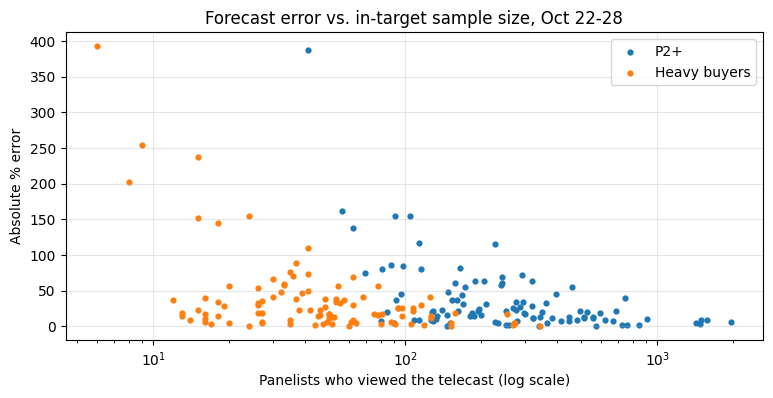

In [11]:
top5 = week.nlargest(5, "err_p2").copy()
usual_start = hist.assign(t=hist["start_ts"].dt.strftime("%H:%M")).groupby(["network_code", "program_name"])["t"].agg(lambda x: x.mode().iat[0])


def lead_in(row):
    """The program that aired right before this telecast on the same network."""
    before = programs[(programs["network_code"] == row["network_code"]) & (programs["end_ts"] <= row["start_ts"])]
    return before.loc[before["end_ts"].idxmax(), "program_name"] if len(before) else ""


misses = pd.DataFrame({
    "program": top5["label"],
    "date": top5["broadcast_date"].dt.strftime("%Y-%m-%d"),
    "weekday": top5["broadcast_date"].dt.day_name(),
    "start": top5["start_ts"].dt.strftime("%H:%M"),
    "usual_start": [usual_start.get((n, p), "") for n, p in zip(top5["network_code"], top5["program_name"])],
    "lead_in": [lead_in(r) for _, r in top5.iterrows()],
    "forecast": top5["p2_fc"].round(2),
    "actual": top5["p2"].round(2),
    "error_pct": (100 * top5["err_p2"]).round(1),
})
display(misses)

# what aired that evening on those networks (to explain the misses)
for _, r in top5.iterrows():
    eve = programs[(programs["network_code"] == r["network_code"]) & (programs["broadcast_date"] == r["broadcast_date"])
                   & (programs["start_ts"].dt.hour >= 17)]
    print(f"\n{r['label']} on {r['broadcast_date']:%Y-%m-%d}:")
    print(eve[["start_ts", "end_ts", "program_name"]].to_string(index=False))

# error vs how many heavy-buyer panelists watched (fewer in-target panelists -> noisier)
hv_n = vm[vm["respondent_id"].isin(heavy_ids)].groupby("telecast_id").size()
p2_n = vm.groupby("telecast_id").size()
week["heavy_panelists"] = hv_n.reindex(week.index).fillna(0)
week["p2_panelists"] = p2_n.reindex(week.index).fillna(0)
print("\nMedian viewing panelists per forecast telecast: P2+", week["p2_panelists"].median(),
      "| heavy buyers", week["heavy_panelists"].median())

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(week["p2_panelists"], 100 * week["err_p2"], s=12, label="P2+")
ax.scatter(week["heavy_panelists"], 100 * week["err_heavy"], s=12, label="Heavy buyers")
ax.set_xscale("log")
ax.set_xlabel("Panelists who viewed the telecast (log scale)")
ax.set_ylabel("Absolute % error")
ax.set_title("Forecast error vs. in-target sample size, Oct 22-28")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Answer:** On **101** telecasts the forecast error is **MAPE 35.8%** for P2+ and **38.6%** for heavy buyers. The medians are only **19.7%** and **21.8%**, and the WAPE is **22.8%** and **24.6%**. A few huge misses drive the mean.

**The five biggest misses** are all *over*-forecasts of **small** programs (actual ratings 0.18–0.67), so even a modest miss in points becomes a large percentage:
- **Sunday, October 27** has three of them: *Krapopolis* (FOX, 388%), *Universal Basic Guys* (FOX, 162%) and *Fire Country* (CBS, 155%). That evening the schedule and the competition changed:
  - On CBS the late NFL game ran long: *60 Minutes* started at 19:35, and *Tracker* and *The Equalizer* moved to 20:44 and 21:44. *Fire Country* was split: 14 minutes at 20:30 and a stub at **22:44–23:00** instead of its usual 21:00 slot. The forecast assumes the usual time and lead-in.
  - FOX's animation block faced **Sunday Night Football, Dallas at San Francisco, on NBC**, the most-watched telecast of the period (33.1 household rating in Lab 3), which pulled viewers away.
- *Accused* (FOX, October 22) and *What Would You Do?* (ABC, October 23) aired at their usual times with the usual lead-ins. These look like ordinary week-to-week variation (episode, competition, sample noise) magnified by tiny ratings: 0.37 and 0.18.

**Why the heavy-buyer forecast is less accurate:** fewer people stand behind it. The median telecast is viewed by **241** P2+ panelists but only **46** heavy-buyer panelists, and the error of a rating grows as the in-target sample shrinks (the scatter plot shows the error widening to the left). Both the history mean and the actual are noisier for heavy buyers. The gap is modest here because heavy buyers are a large audience, 20% of adults. For Kestrel buyers it would be much worse.

**Two things a better forecast would use:**
1. **The schedule itself:** start time, duration, lead-in, competition and known events (NFL overruns and preemptions, World Series games, specials, election night). A forecast is *content × audience × inventory*: the same program in a shifted slot or against SNF is a different product.
2. **More and smarter history:** more weeks (and last year's same week), recency weights for trends such as premiere decay, and **shrinking small-sample target ratings** toward the program's P2+ trend times its typical target ratio. Then heavy-buyer forecasts borrow stability from the much larger P2+ sample.

## Task 5.1 — The plan

In [12]:
BUDGET = 1_000_000
weekly_airings = (prog["telecasts"] / (N_DAYS / 7)).round().clip(lower=1)
MAX_SPOTS_PER_TELECAST = 2

# buy the cheapest target CPM first, up to 2 spots in each of the program's weekly telecasts
plan = prog[["target_CPM", "index", "composition", "cost_30s", "target_viewers", "adults_viewers"]].copy()
plan["max_spots"] = (weekly_airings * MAX_SPOTS_PER_TELECAST).astype(int)
plan["spots"] = 0
left = BUDGET
for name in plan.sort_values("target_CPM").index:
    n = int(min(plan.loc[name, "max_spots"], left // plan.loc[name, "cost_30s"]))
    plan.loc[name, "spots"] = n
    left -= n * plan.loc[name, "cost_30s"]
plan = plan[plan["spots"] > 0].copy()
plan["cost"] = plan["spots"] * plan["cost_30s"]
plan["target_impressions_M"] = plan["spots"] * plan["target_viewers"] / 1e6
plan["adult_impressions_M"] = plan["spots"] * plan["adults_viewers"] / 1e6
display(plan[["spots", "cost_30s", "cost", "target_impressions_M", "adult_impressions_M", "target_CPM", "index", "composition"]]
        .round({"cost_30s": 0, "cost": 0, "target_impressions_M": 2, "adult_impressions_M": 2, "target_CPM": 2, "index": 0, "composition": 3}))

plan_cost = plan["cost"].sum()
plan_imp = plan["target_impressions_M"].sum()
print("Plan cost ($):", round(plan_cost))
print("Plan target impressions (M):", f"{plan_imp:.1f}")
print("Unspent ($):", round(BUDGET - plan_cost))
print("Plan target CPM ($):", f"{plan_cost / (plan_imp * 1000):.2f}")
print("Share of adult impressions on heavy buyers:", f'{plan_imp / plan["adult_impressions_M"].sum():.3f}')
print("Target GRPs:", f'{100 * plan_imp * 1e6 / sizes["Heavy buyers (3+)"]:.1f}')

,spots,cost_30s,cost,target_impressions_M,adult_impressions_M,target_CPM,index,composition
label,,,,,,,,
Dancing with the Stars (ABC),2,158600.0,317200.0,3.13,16.41,101.39,97.0,0.191
Hannity (FNC),10,39900.0,399000.0,4.17,27.51,95.71,77.0,0.152
Unsellable Houses (HGTV),6,12900.0,77400.0,1.90,7.65,40.66,127.0,0.249
Halloween Wars (FOOD),4,9700.0,38800.0,0.65,2.84,59.90,116.0,0.228
Grotesquerie (FX),12,7592.0,91104.0,1.49,7.92,61.11,96.0,0.188


Plan cost ($): 923504
Plan target impressions (M): 11.3
Unspent ($): 76496
Plan target CPM ($): 81.44
Share of adult impressions on heavy buyers: 0.182
Target GRPs: 22.9


## Task 5.2 — Recommendation
**Answer:** For Kestrel's $1,000,000 week, I recommend buying **34 :30 spots for $923,504** on the programs that deliver heavy buyers most cheaply:
- 6 spots in *Unsellable Houses (HGTV)*, target CPM $41;
- 4 in *Halloween Wars (FOOD)*, $60;
- 12 in *Grotesquerie (FX)*, $61;
- 10 in *Hannity (FNC)*, $96;
- 2 in *Dancing with the Stars (ABC)*, $101.

I picked them by **target CPM**, using volume and index only as tie-breakers. The plan delivers **11.3 M heavy-buyer impressions** (22.9 target GRPs) at a **target CPM of $81.44**. Sunday and Monday Night Football and NCIS cost $148–174 per thousand heavy buyers, so they did not make the cut. The remaining **$76,496** is too little for another DWTS spot. It could add about 3–4 more spots on HGTV, FOOD or FX, or be held for a make-good negotiation. The delivery is **not certain**: in Task 4 my heavy-buyer forecasts missed by **38.6% on average** (median 21.8%). This plan also leans on small cable programs with only 11–25 heavy-buyer panelists per telecast, so a ±25% swing in delivered impressions is realistic, though errors partly cancel across 34 spots. I would therefore buy it with an audience **guarantee and make-goods**. About **82% of the impressions go to people who are not heavy buyers** (composition 0.182), the unavoidable waste of TV, since even the best program is only 25% heavy buyers. After the week I would run a **post-buy**: actual heavy-buyer impressions and reach per spot from the November panel against this plan, with make-goods claimed where it fell short. Because fused data cannot link exposure to purchase, I would also measure **sales or brand lift** among exposed vs. unexposed homes, through ACR exposure matched to retail or loyalty data, or a brand-lift survey.